In [294]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
from IPython.display import display
warnings.simplefilter("ignore")
%matplotlib inline

In [295]:
data = pd.read_csv("Titanic-Dataset.csv")
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [296]:
# size + типы данных
display(data.shape)
data.info()

(891, 12)

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [297]:
display(data.describe().T) # числовые признаки
# пропуски
null = data.isna().sum()
display(pd.DataFrame({"пропусков": null, "доля, %": (null / len(data) * 100).round(1)})[null > 0])
# дубликаты
print('Полных дубликатов:', data.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


,пропусков,"доля, %"
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


Полных дубликатов: 0


Survived
0    549
1    342
Name: count, dtype: int64

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

<Axes: xlabel='Survived', ylabel='count'>

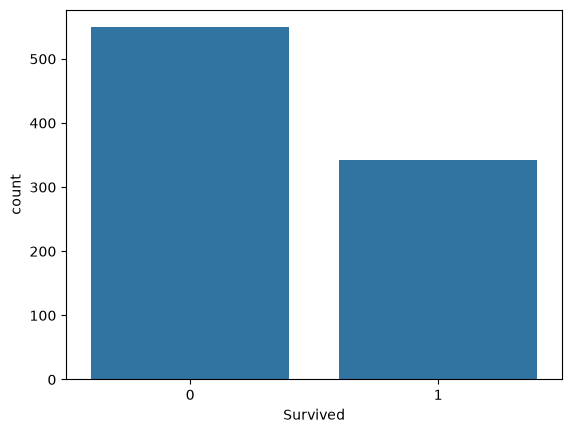

In [298]:
# Survived 1 - выжил, 0 - погиб
display(data["Survived"].value_counts())
display(data["Survived"].value_counts(normalize=True))

sns.countplot(x="Survived", data=data)

In [299]:
# сколько уникальных значений в подозрительных столбцах
data[["PassengerId", "Name", "Ticket", "Fare", "Cabin"]].nunique()

PassengerId    891
Name           891
Ticket         681
Fare           248
Cabin          147
dtype: int64

ВЫВОДЫ:

891 пассажир, 12 столбцов. Целевая переменная Survived (1 - выжил, 0 - погиб).

Распределение целевой: выжили около 38%, погибли около 62%. Классы несбалансированы.

Пропуски: Age (около 20%), Cabin (около 77%), Embarked (2 значения).
Age заполним медианой, Embarked - самым частым значением, Cabin не используем.

Дубликатов нет.

Признаки с риском утечки и бессмысленного запоминания: PassengerId,
Name и Ticket (почти у каждого пассажира уникальны), Cabin (в основном пропуски).
Модель может запомнить конкретных людей вместо закономерностей, поэтому эти
признаки убираем.

Признаки Sex, Pclass, Embarked, Fare требуют отдельной обработки.
Sex и Embarked хранятся как текст (male/female, S/C/Q), а модели работают только с числами,
поэтому текст нужно перевести в числа. Pclass хранится числом (1, 2, 3) - это названия классов билета. Также требуется масштабирование признаков.

In [300]:
# преобразования
data_new = data.copy()
data_new["Family"] = data_new["SibSp"] + data_new["Parch"]

# обращение из имени ("среднее" между Name Age Sex)
data_new["Title"] = data_new["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
data_new["Title"] = data_new["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
data_new["Title"] = data_new["Title"].where(data_new["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
display(data_new["Title"].value_counts())

data_new = data_new.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "SibSp", "Parch"])
data_new.head()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

,Survived,Pclass,Sex,Age,Fare,Embarked,Family,Title
0,0,3,male,22.0,7.2500,S,1,Mr
1,1,1,female,38.0,71.2833,C,1,Mrs
2,1,3,female,26.0,7.9250,S,0,Miss
3,1,1,female,35.0,53.1000,S,1,Mrs
4,0,3,male,35.0,8.0500,S,0,Mr


In [301]:
from sklearn.model_selection import train_test_split

y = data_new["Survived"]
X = data_new.drop(columns=["Survived"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# stratify=y - доля выживших одинакова в train и test
# random_state=42 - разбиение всегда одинаковое
print("Доля выживших в train:", round(y_train.mean(), 3))
print("Доля выживших в test:", round(y_test.mean(), 3))

Доля выживших в train: 0.383
Доля выживших в test: 0.385


In [302]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num = ["Age", "Fare", "Family"]            # числовые
cat = ["Pclass", "Sex", "Embarked", "Title"]        # категориальные

# для деревьев: без масштабирования
preprocess_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num), # медиана для чисел
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")), # часто встречаемое для категорий
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat),
])

# для SVM и KNN: то же самое + масштабирование чисел
preprocess_scaled = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),# из значения признака вычетает среднее и делит на среднеквадратичное отклонение(разброс)
    ]), num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat),
])

In [303]:
# fit_transform - сначала считает  по train и применяет
X_train_sc = preprocess_scaled.fit_transform(X_train)
X_test_sc = preprocess_scaled.transform(X_test)

print(X_train.shape, "->", X_train_sc.shape)

# в таблицу с названиями столбцов
cols_names = preprocess_scaled.get_feature_names_out()
display(pd.DataFrame(X_train_sc, columns=cols_names).head())
print("Пропусков в train:", np.isnan(X_train_sc).sum(), " в test:", np.isnan(X_test_sc).sum())

(712, 7) -> (712, 16)


,num__Age,num__Fare,num__Family,cat__Pclass_1,cat__Pclass_2,cat__Pclass_3,cat__Sex_female,cat__Sex_male,cat__Embarked_C,cat__Embarked_Q,cat__Embarked_S,cat__Title_Master,cat__Title_Miss,cat__Title_Mr,cat__Title_Mrs,cat__Title_Rare
0,-0.081135,0.513812,-0.556339,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,-0.081135,-0.662563,-0.556339,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,-0.081135,3.955399,-0.556339,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,-0.887827,-0.467874,0.073412,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,0.110934,-0.115977,0.703162,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


Пропусков в train: 0  в test: 0


ВЫВОДЫ:

Пропуски: Age заполнили медианой. Embarked заполнили самым частым значением. Cabin удалили (77% пропусков).

Категориальные признаки: Pclass, Sex, Embarked закодировали One-Hot (отдельный столбец
0/1 для каждой категории), чтобы модель не увидела ложную близость категорий (модель может считать Q «больше» S).
handle_unknown="ignore" - если в test встретится неизвестная категория, ошибки не будет.

Новыt признакb: Family = SibSp + Parch - количество родственников на борту. Title - обращение из имени (Mr, Mrs, Miss, Master, остальные редкие объединены в Rare). Title содержит сразу пол, возраст (Master - мальчик) и статус. Удалили PassengerId, Name, Ticket, Cabin - они почти уникальны и позволяют модели запомнить людей.

Все параметры (медиана, мода, категории, среднее и разброс) считаются только по train, test используется только для оценки.

Масштабирование: нужно SVM и KNN (считают расстояния, Fare(до 500) иначе пересилит Age).
Деревьям не нужно: они сравнивают признак с порогом.

Dummy baseline
Accuracy 0.6145251396648045
Precision 0.0
Recall 0.0
F1 0.0


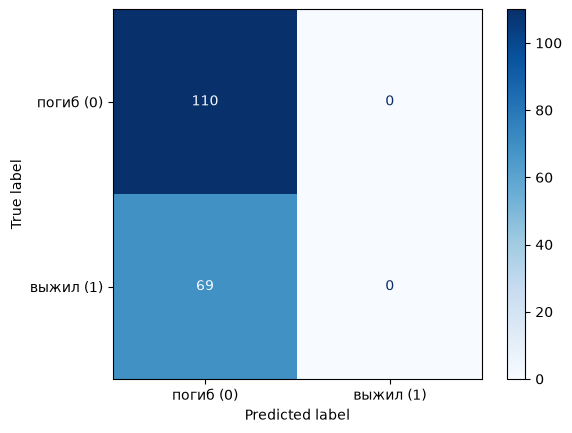

In [304]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

# Всегда предсказывает самый частый класс - погибшие
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)

print("Dummy baseline")
print("Accuracy", accuracy_score(y_test, pred))
print("Precision", precision_score(y_test, pred, zero_division=0))
print("Recall", recall_score(y_test, pred, zero_division=0))
print("F1", f1_score(y_test, pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["погиб (0)", "выжил (1)"], cmap="Blues"
)
plt.show()

ВЫВОДЫ:

Dummy baseline всегда отвечает "погиб" (самый частый класс). 

False Positive (FP): модель сказала "выжил", а пассажир погиб.
False Negative (FN): модель сказала "погиб", а пассажир выжил.

TN = 110: погибших модель назвала погибшими. Верно.

FP = 0: погибших, названных выжившими - их нет.

FN = 69: выжившие, названные погибшими - равен числу всех выживших в тесте.

TP = 0: выживших модель не нашла.

Отсюда метрики: 

Precision = TP / (TP+FP) = 0/0, ставим 0 (из-за zero_division=0) - смотрим только объекты, которые модель назвала классом "1", насколько верить положительному прогнозу. 

Recall = TP / (TP + FN) = 0/69 = 0 - смотрим все истинные объекты класса "1", считаем сколько положительных объектов нашли. 

F1 = 2 * Precision * Recall / (Precision + Recall) =  0 - гармоническое среднее Precision и Recall.

Accuracy = (TP+TN) / (TP+TN+FP+FN) = (110+0)/179 = 0.615  - доля всех правильных ответов.

Поэтому одной Accuracy нельзя оценивать качество при несбалансированных классах, основной метрикой берем F1 для класса 1.

In [305]:
from sklearn.tree import DecisionTreeClassifier

tree = Pipeline([
    ("prep", preprocess_tree),
    ("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)),
])

In [306]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

rf = Pipeline([
    ("prep", preprocess_tree),
    ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)),
])

gb = Pipeline([
    ("prep", preprocess_tree),
    ("model", GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=42)),
])

In [307]:
from sklearn.svm import SVC

svm = Pipeline([
    ("prep", preprocess_scaled),
    ("model", SVC(C=1.0, kernel="rbf", gamma="scale", probability=True, random_state=42)),
])

In [308]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([
    ("prep", preprocess_scaled),
    ("model", KNeighborsClassifier(n_neighbors=7, weights="distance")),
])

In [309]:
from sklearn.metrics import roc_auc_score

# функция оценки
def evaluate(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]   # вероятность класса "выжил"
    pred_train = model.predict(X_train)
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba),
        "f1_train": f1_score(y_train, pred_train, zero_division=0),   # для проверки переобучения
    }

In [310]:
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold

grids = {
    "Decision Tree": (tree, {
        "model__max_depth": [3, 4, 5, 6, 8],
        "model__min_samples_leaf": [1, 3, 5, 10, 20],
        "model__criterion": ["gini", "entropy"]}),

    "Random Forest": (rf, {
        "model__max_depth": [4, 6, 8, None],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": ["sqrt", 0.5]}),

    "Gradient Boosting": (gb, {
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.7, 1.0]}),

    "SVM": (svm, {
        "model__C": [0.5, 1, 3, 10],
        "model__gamma": ["scale", 0.05, 0.1, 0.3],}),

    "KNN": (knn, {
        "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]}),
}

# 5 блоков, повторённых 3 раза с разным перемешиванием: менее случайный выбор параметров
# кросс-валидация идет ТОЛЬКО внутри train, test не используется
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

models_res = {}
cv_scores = {}
for name, (pipe, grid) in grids.items():
    search = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    models_res[name] = search.best_estimator_ # лучшая модель
    cv_scores[name] = search.best_score_
    print(name, search.best_params_, "| F1 на кросс-валидации =", round(search.best_score_, 3))

Decision Tree {'model__criterion': 'entropy', 'model__max_depth': 3, 'model__min_samples_leaf': 1} | F1 на кросс-валидации = 0.762
Random Forest {'model__max_depth': 8, 'model__max_features': 0.5, 'model__min_samples_leaf': 1} | F1 на кросс-валидации = 0.773
Gradient Boosting {'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 200, 'model__subsample': 0.7} | F1 на кросс-валидации = 0.773
SVM {'model__C': 1, 'model__gamma': 0.05} | F1 на кросс-валидации = 0.77
KNN {'model__n_neighbors': 5, 'model__p': 2, 'model__weights': 'uniform'} | F1 на кросс-валидации = 0.749


Так как параметры изначально выбраны произвольно, то подобрали гиперпараметры через GridSearchCV по F1 на кросс-валидации (5 блоков, 3 повтора) только внутри обучающей выборки. Тестовая выборка при подборе не используется: параметры выбираются по train, а test остается для финальной оценки.

In [311]:
results = []
for name, model in models_res.items():
    model.fit(X_train, y_train)
    results.append(evaluate(name, model))

results = pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True)
results["F1 > 0.70"] = results["f1"] > 0.70
display(results.round(3))

,model,accuracy,precision,recall,f1,roc_auc,f1_train,F1 > 0.70
0,Gradient Boosting,0.838,0.823,0.739,0.779,0.847,0.907,True
1,SVM,0.838,0.823,0.739,0.779,0.847,0.775,True
2,Decision Tree,0.832,0.800,0.754,0.776,0.864,0.785,True
3,Random Forest,0.827,0.828,0.696,0.756,0.854,0.904,True
4,KNN,0.810,0.787,0.696,0.738,0.856,0.809,True


Анализ точности (Precision) и полноты (Recall):

Точность (Precision): Наилучшие показатели у Random Forest (0.828), Gradient Boosting и SVM (0.823). Это говорит о высоком качестве предсказаний положительного класса (если модель прогнозирует, что пассажир выжил, вероятность ошибки минимальна).

Полнота (Recall): Максимальное значение зафиксировано у Decision Tree (0.754), что свидетельствует о способности дерева решений лучше находить реальных выживших пассажиров среди всех фактически спасшихся.

Качество ранжирования классов (ROC-AUC):

Наивысшую способность разделять классы по вероятностям показало Decision Tree (0.864), за ним следуют KNN (0.856) и Random Forest (0.854). Это указывает на хорошее качество распределения вероятностей прогнозов независимо от выбранного порога классификации.

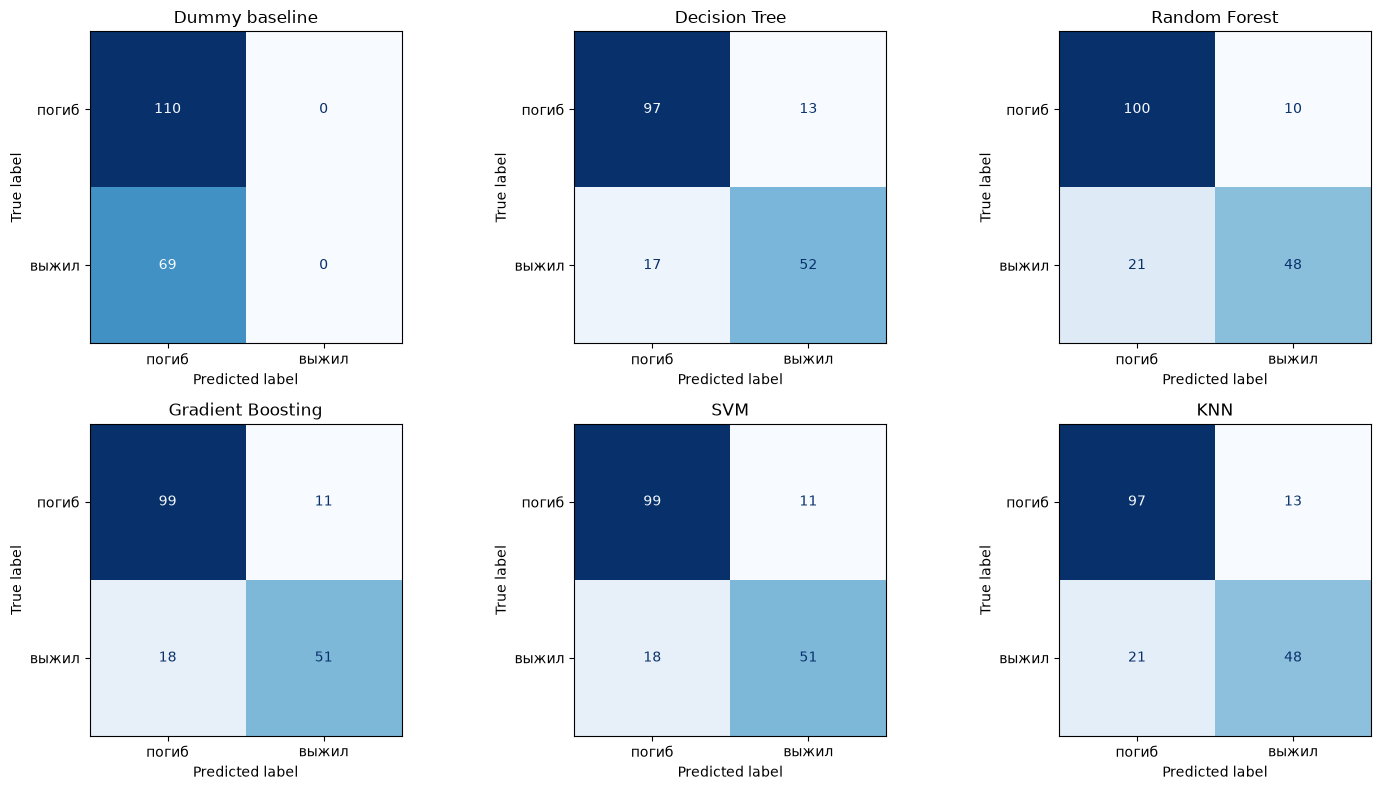

,model,TN,FP,FN,TP
0,Dummy baseline,110,0,69,0
1,Decision Tree,97,13,17,52
2,Random Forest,100,10,21,48
3,Gradient Boosting,99,11,18,51
4,SVM,99,11,18,51
5,KNN,97,13,21,48


In [312]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# confusion matrix каждой модели
all_models = {"Dummy baseline": baseline, **models_res}

fig, axs = plt.subplots(2, 3, figsize=(15, 8))
rows = []
for ax, (name, model) in zip(axs.ravel(), all_models.items()):
    pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, ax=ax, display_labels=["погиб", "выжил"], cmap="Blues", colorbar=False)
    ax.set_title(name)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
plt.tight_layout()
plt.show()

display(pd.DataFrame(rows))

ВЫВОДЫ:

False Positive (FP) - модель сказала "выжил", а пассажир погиб. 

False Negative (FN) - модель сказала "погиб", а пассажир выжил.

Для этой задачи FP и FN означают разные ошибки: FP снижает Precision (когда модель говорит "выжил", ей не всегда можно верить), FN снижает Recall (часть выживших модель не находит). F1 учитывает обе ошибки.

У моделей FN больше, чем FP: они чаще пропускают выживших, чем ошибочно "спасают" погибших (Recall ниже Precision), так как погибших в данных больше. 
Dummy baseline ни разу не предсказывает "выжил": FP = 0, но FN = 69.

In [317]:
# сравнение качества на обучающей и тестовой выборках (F1)
gap = results[["model", "f1_train", "f1"]].copy()
gap["разница"] = gap["f1_train"] - gap["f1"]
print("После подбора параметров:")
display(gap.round(3))

После подбора параметров:


,model,f1_train,f1,разница
0,Gradient Boosting,0.907,0.779,0.129
1,SVM,0.775,0.779,-0.004
2,Decision Tree,0.785,0.776,0.009
3,Random Forest,0.904,0.756,0.149
4,KNN,0.809,0.738,0.070


ВЫВОД: 

Наилучшие результаты на тестовой выборке показали Gradient Boosting и SVM со значением метрики F1, равным 0.779.

Decision Tree и KNN демонстрируют минимальный разрыв между train и test. У SVM разница отрицательная (-0.004), а у Decision Tree составляет всего 0.009, что говорит об отличной обобщающей способности и эффективном подборе параметров регуляризации.

,Decision Tree,Random Forest,Gradient Boosting
Sex,0.000,0.237,0.087
Title,0.654,0.208,0.323
Fare,0.112,0.181,0.242
Age,0.000,0.156,0.151
Pclass,0.159,0.115,0.107
Family,0.076,0.071,0.063
Embarked,0.000,0.032,0.027


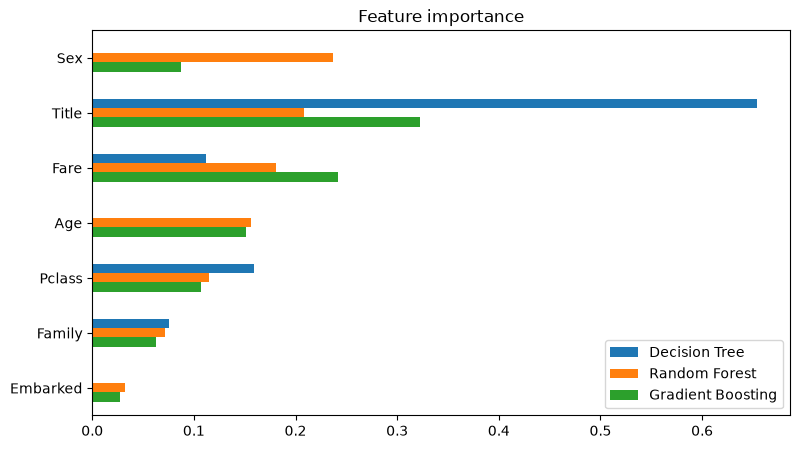

In [314]:
# важность признаков (для моделей на деревьях)
def get_importance(model):
    names = [n.split("__")[1] for n in model.named_steps["prep"].get_feature_names_out()]
    imp = pd.Series(model.named_steps["model"].feature_importances_, index=names)
    # части One-Hot (Sex_male, Sex_female) складываем в один признак
    return imp.groupby(lambda n: n.split("_")[0]).sum()

imp_df = pd.DataFrame({
    "Decision Tree": get_importance(models_res["Decision Tree"]),
    "Random Forest": get_importance(models_res["Random Forest"]),
    "Gradient Boosting": get_importance(models_res["Gradient Boosting"]),
}).sort_values("Random Forest", ascending=False)

display(imp_df.round(3))

imp_df.plot(kind="barh", figsize=(9, 5))
plt.gca().invert_yaxis()
plt.title("Feature importance")
plt.show()

ВЫВОДЫ:

Наиболее важные признаки: 

у Decision Tree - Title, Pclass, Family; 

у Random Forest - Title, Sex, Fare; 

у Gradient Boosting - Title, Fare, Age. 

Наименее важный у всех - Embarked.

Сравнение: у всех трех моделей один из главных признак - Title (обращение). Title почти повторяет Sex (Mr и Master - мужчины, Mrs и Miss - женщины) и дополнительно содержит возраст (Master - мальчик), поэтому одно дерево опирается в основном на Title и Pclass, а Sex ему уже почти не нужен (важность 0). Это пример того, что связанные признаки делят между собой важность. Random Forest и Gradient Boosting распределяют важность между несколькими признаками, в том числе непрерывными Fare и Age (их можно разбивать по многим порогам, поэтому у них важность по impurity выше). Gradient Boosting сильнее Random Forest использует Fare и Age, а Random Forest - Sex; при этом ведущие признаки у них одни и те же.

Можно ли утверждать, что важный признак является причиной выживания? Нет. 

Feature importance показывает только, насколько сильно модель использовала признак для предсказания, то есть отражает корреляцию.

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv_pred = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# нужен ли масштаб: сравниваем F1 на кросс-валидации внутри train (test не трогаем)
svm_ns = Pipeline([("prep", preprocess_tree), ("model", SVC(random_state=42))])
knn_ns = Pipeline([("prep", preprocess_tree), ("model", KNeighborsClassifier(n_neighbors=7, weights="distance"))])

rows = []
for name, with_scaling, without_scaling in [("SVM", svm, svm_ns), ("KNN", knn, knn_ns)]:
    rows.append({
        "model": name,
        "F1 (CV) с масштабированием": cross_val_score(with_scaling, X_train, y_train, cv=cv_pred, scoring="f1").mean(),
        "F1 (CV) без масштабирования": cross_val_score(without_scaling, X_train, y_train, cv=cv_pred, scoring="f1").mean(),
    })
display(pd.DataFrame(rows).round(3))

,model,F1 (CV) с масштабированием,F1 (CV) без масштабирования
0,SVM,0.757,0.444
1,KNN,0.724,0.649


ВЫВОДЫ:

SVM и KNN основаны на расстояниях между объектами. Без масштабирования расстояние почти целиком определяется признаком с большими числами (Fare), а Age, Family и категориальные признаки (0/1) почти не влияют, хотя на самом деле они не менее важны, поэтому качество падает.

StandardScaler приводит числовые признаки к одному масштабу (среднее 0, разброс 1), и каждый признак вносит сопоставимый вклад в расстояние.

Для деревьев, Random Forest и Gradient Boosting масштабирование не нужно: они сравнивают значение признака с порогом, и масштаб на результат не влияет.

In [318]:
# анализ ошибок лучшей модели
best_name = results.iloc[0]["model"]
best_model = models_res[best_name]
print("Лучшая модель:", best_name)

proba_best = best_model.predict_proba(X_test)[:, 1]
pred_best = best_model.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred_best).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

# таблица test + ответы модели
err = X_test.copy()
err["true"] = y_test
err["pred"] = pred_best
err["proba"] = proba_best
err["is_fp"] = (err["pred"] == 1) & (err["true"] == 0)
err["is_fn"] = (err["pred"] == 0) & (err["true"] == 1)
err["error"] = err["is_fp"] | err["is_fn"]
err["AgeGroup"] = pd.cut(err["Age"], [0, 12, 18, 40, 60, 100],
                         labels=["до 12", "12-18", "18-40", "40-60", "60+"]).astype(object).fillna("нет данных")

def error_table(col):
    g = err.groupby(col)
    return pd.DataFrame({"пассажиров": g.size(), "FP": g["is_fp"].sum(),
                         "FN": g["is_fn"].sum(), "доля ошибок": g["error"].mean().round(3)})

for col in ["Sex", "Pclass", "AgeGroup"]:
    display(error_table(col))

Лучшая модель: Gradient Boosting
TN=99  FP=11  FN=18  TP=51


,пассажиров,FP,FN,доля ошибок
Sex,,,,
female,61,5,2,0.115
male,118,6,16,0.186


,пассажиров,FP,FN,доля ошибок
Pclass,,,,
1,45,6,6,0.267
2,34,1,2,0.088
3,100,4,10,0.140


,пассажиров,FP,FN,доля ошибок
AgeGroup,,,,
12-18,17,0,0,0.000
18-40,79,3,10,0.165
40-60,23,3,2,0.217
60+,6,1,1,0.333
до 12,14,1,2,0.214
нет данных,40,3,3,0.150


Выводы: 
Анализ ошибок лучшей модели (Gradient Boosting)

Соотношение типов ошибок (Confusion Matrix):

Матрица ошибок показала: TN = 99, FP = 11, FN = 18, TP = 51. Ложноотрицательные ошибки FN = 18 преобладают над ложноположительными FP почти в 1.6 раза. 

Модель чаще совершает ошибку следующего рода - классифицирует реально выжившего пассажира как погибшего, что снижает показатель полноты Recall. 

Это обусловлено общим дисбалансом классов (число погибших на «Титанике» превышает число спасшихся).

Анализ ошибок:

По полу (Sex): Модель заметно чаще ошибается на мужчинах (доля ошибок 18.6%, из них FN = 16$), чем на женщинах (доля ошибок 11.5%). 

Модель идеально классифицировала подростков 12–18 лет (доля ошибок 0%). Наибольший процент ошибок наблюдается в категории 60+ (33.3%) из-за малой выборки объектов.

Причины ошибок: 

Модель ошибается на «нетипичных» пассажирах — например, мужчинах из 3-го класса, которые смогли спастись (модель относит их к FN).

Проверка утечки данных: 

Высокое качество модели не обусловлено утечкой данных. Уникальные идентификаторы пассажиров (PassengerId, Name, Ticket, Cabin) были заранее удалены или преобразованы в обобщённые признаки (например, обращение Title).